### Skull Strip MRIs

This can take up to 4 hours (Ryzen 5800X, RTX 4070 Super, 32GB RAM)

Error: Missing MRI/PET file for dataset/pup/OAS31093_PIB_d0538/OAS31093_PIB_PUPTIMECOURSE_d0538/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS30258_PIB_d0063/OAS30258_PIB_PUPTIMECOURSE_d0063/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS30699_PIB_d0662/OAS30699_PIB_PUPTIMECOURSE_d0662/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS30322_AV45_d3851/OAS30322_AV45_PUPTIMECOURSE_d3851/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS30899_PIB_d2324/OAS30899_PIB_PUPTIMECOURSE_d2324/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS30920_PIB_d0560/OAS30920_PIB_PUPTIMECOURSE_d0560/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS30178_PIB_d0049/OAS30178_PIB_PUPTIMECOURSE_d0049/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS31005_AV45_d1649/OAS31005_AV45_PUPTIMECOURSE_d1649/pet_proc/
Error: Missing MRI/PET file for dataset/pup/OAS30093_AV45_d0056/OAS30093_AV45_PUPTIMECOURSE_d0056/pet_proc/
Error: Missing MRI/PET file for dataset/

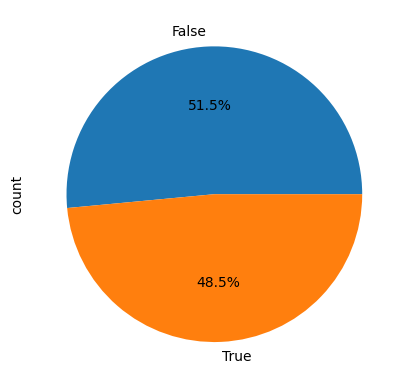

In [49]:
import os
import glob
import shutil
import numpy as np
import pandas as pd
from utils.preprocessing import Utils

replace = False
dataset_info = "dataset/balanced_dataset.csv"
dataset_path = "dataset/pup"

# List of sessions directories
pup_sessions = glob.glob(dataset_path + "/*/*/pet_proc/")


count = 0
processes = []
failed = []

def batch_processes(processes):
    global count, failed
    print(f"Progress: {count}/{len(pup_sessions)}")
    print("Waiting for Batch...")
    for (session, process) in processes:
        process.wait()
        if process.poll() != 0:
            failed.append(session.split("/")[-4])
            print(f"Error: Failed to strip - {session}")
        else:
            print("Stripped:", session)
    count += len(processes)
    return []

# Iterate through all PUP sessions
for session in pup_sessions:
    # List of session files
    files = os.listdir(session)

    # Check if scans exists
    pet_scan = any([("n_msum_SUVR_g8.4dfp.img" in i) for i in files])
    if (not pet_scan) or "T1.nii" not in files:
        count += 1
        print(f"Error: Missing MRI/PET file for {session}")
        failed.append(session.split("/")[-4])
        continue

    # Checks if skull has already been stripped
    part_stripped = any([("T1_stripped_tmp" in i) for i in files])
    stripped = "T1_stripped.nii.gz" in files
    if not part_stripped and stripped and not replace:
        count += 1
        continue

    # Start command line process
    mri_path = os.path.join(os.getcwd(), session, "T1")
    
    processes.append((session, Utils.skullstrip_mri(mri_path, mode="B", multi=True)))

    # Wait if process no. equivalent to half of logical cores
    if len(processes) >= os.cpu_count() / 2:
        processes = batch_processes(processes)

# Wait for remaining processes
processes = batch_processes(processes)
print(f"Progress: {count}/{len(pup_sessions)}")
print("Finished")
print(f"{len(failed)} Failed")

print("Failed:", failed)
if len(failed) > 0:
    df = pd.read_csv(os.path.join(os.getcwd(), dataset_info))
    print(df['label'].value_counts())
    df = df[~df['OASISID'].isin([x.split("_")[0] for x in failed])]
    df.to_csv(os.path.join(os.getcwd(), dataset_info), index=False)
    print(df['label'].value_counts())
    df['label'].value_counts().plot.pie(autopct='%1.1f%%')
for fail in failed:
    print("Removing:", os.path.join(os.getcwd(), dataset_path, fail))
    shutil.rmtree(os.path.join(os.getcwd(), dataset_path, fail))



(256, 256, 256)


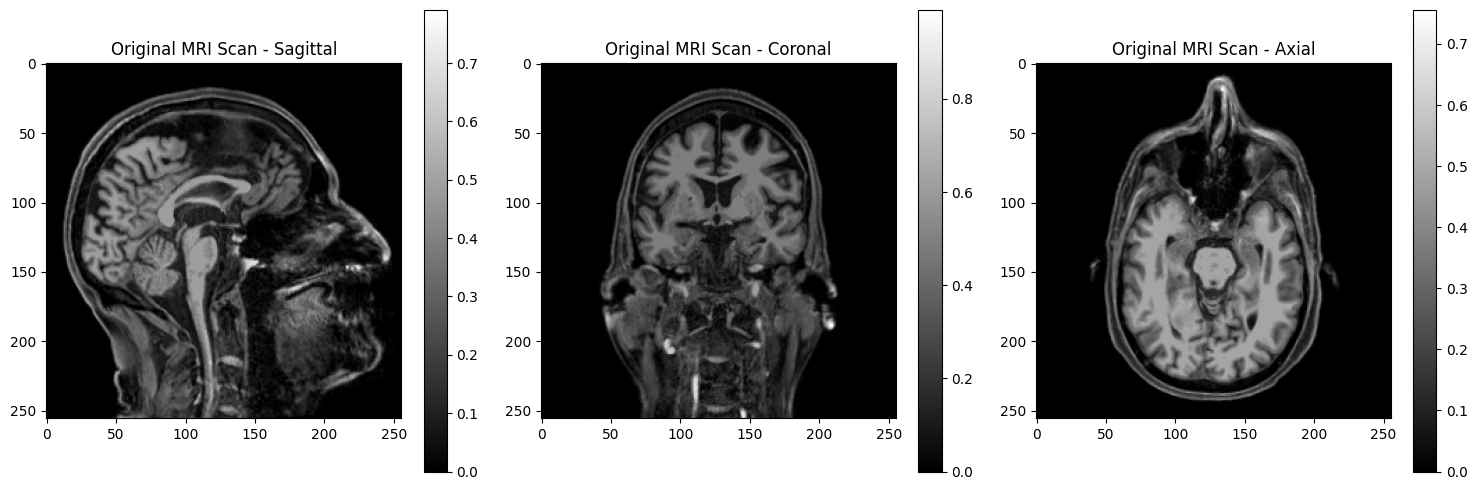

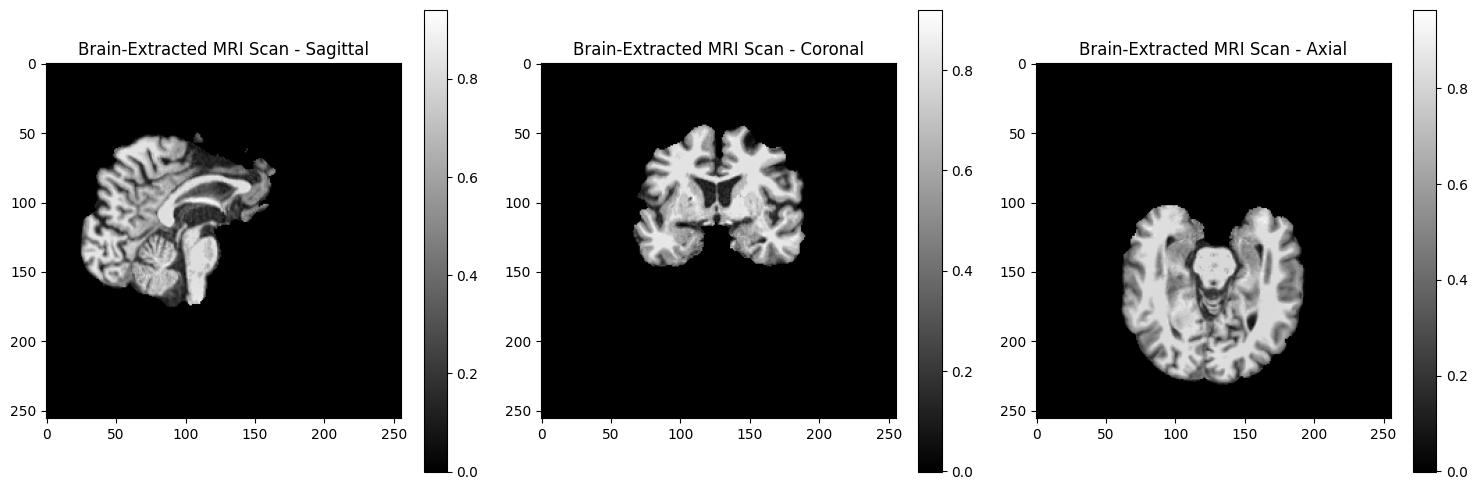

In [80]:
from utils.visualize import plot_central_slices


pup_ses = pup_sessions[18]

# Load the original MRI data (non-processed)
mri_file = os.path.join(os.getcwd(), pup_ses, "T1.nii")
mri_data = Utils.read_nifti_file(mri_file)
mri_data = Utils.normalize_volume(mri_data)

# Load the skull stripped MRI data (processed)
proc_mri_file = os.path.join(os.getcwd(), pup_ses, "T1_stripped.nii.gz")
proc_mri_data = Utils.read_nifti_file(proc_mri_file)
proc_mri_data = Utils.normalize_volume(proc_mri_data)
print(proc_mri_data.shape)


# Visualize the original and skull stripped
plot_central_slices(mri_data, "Original MRI Scan", 'gray')
plot_central_slices(proc_mri_data, "Brain-Extracted MRI Scan", 'gray')



### Visualise PET Data and apply mask

dataset/pup/OAS31446_PIB_d0070/OAS31446_PIB_PUPTIMECOURSE_d0070/pet_proc/
(256, 256, 256)
(256, 256, 256)


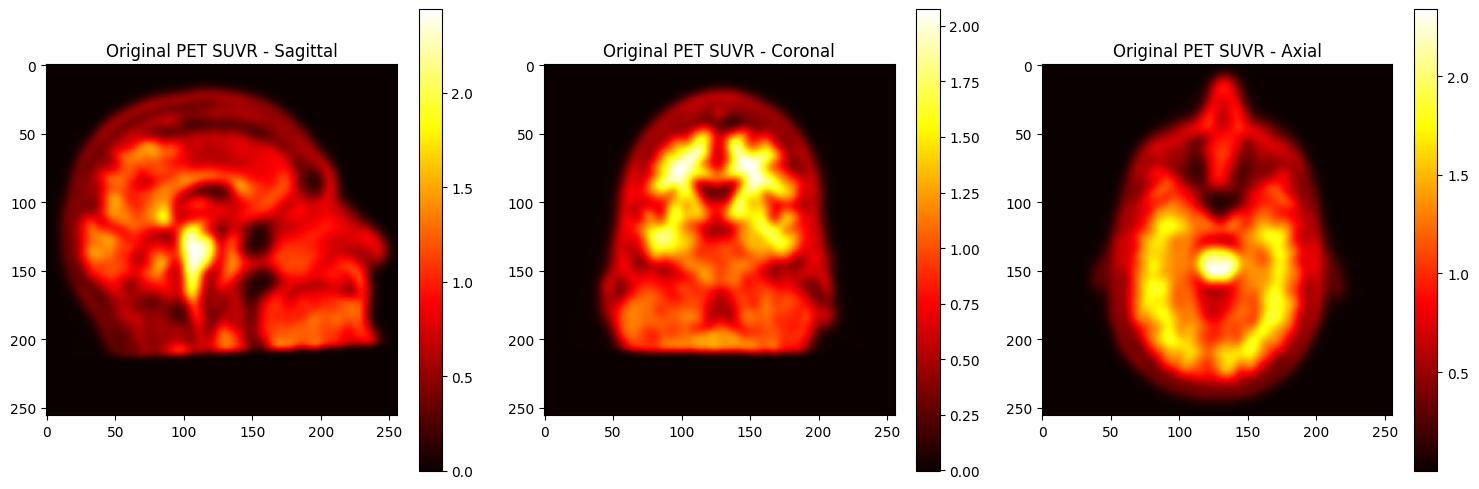

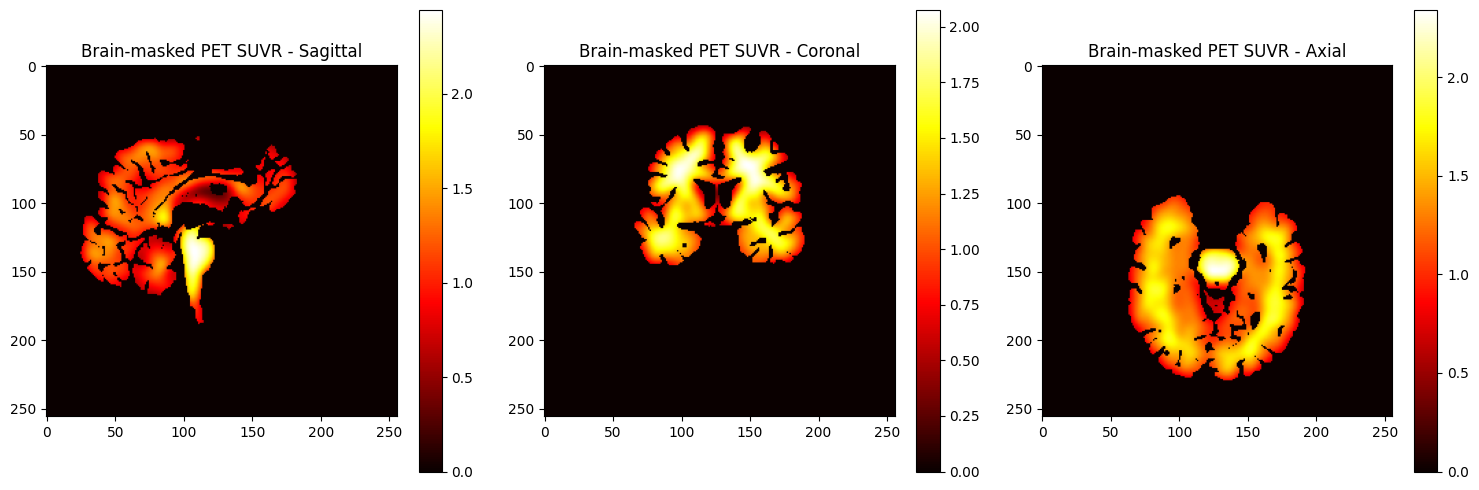

Mean SUVR in brain: 0.8275
Max SUVR in brain: 2.4446


In [81]:
from scipy import ndimage
from matplotlib import colormaps


# print(list(colormaps))


pup_ses = pup_sessions[18]
print(pup_ses)

# Load the SUVR PET data (this is the processed image ready for analysis)
pet_file = glob.glob(os.path.join(pup_ses, "*n_msum_SUVR_g8.4dfp.hdr"))[0]
pet_data, pet_affine = Utils.load_4dfp(pet_file)
pet_data = np.squeeze(pet_data)
print(pet_data.shape)

# Load the brain mask
mask_file = os.path.join(pup_ses, "BrainMask.4dfp.hdr")
mask_data, mask_affine = Utils.load_4dfp(mask_file)
mask_data = np.squeeze(mask_data)
print(mask_data.shape)

# Apply binary mask to get brain-only PET data
# Convert mask to boolean
mask_bool = mask_data > 0
masked_pet_data = pet_data.copy()
masked_pet_data[~mask_bool] = 0  # Set non-brain voxels to zero

pet_data = pet_data[:, ::-1, :]
masked_pet_data = masked_pet_data[:, ::-1, :]

pet_data = ndimage.rotate(pet_data, 90, axes=(1,2), reshape=False)
masked_pet_data = ndimage.rotate(masked_pet_data, 90, axes=(1,2), reshape=False)

# Visualize the original and masked data
plot_central_slices(pet_data, "Original PET SUVR")
plot_central_slices(masked_pet_data, "Brain-masked PET SUVR")

# Extract values for analysis
brain_values = pet_data[mask_bool]
print(f"Mean SUVR in brain: {np.mean(brain_values):.4f}")
print(f"Max SUVR in brain: {np.max(brain_values):.4f}")

### Split the data into training and validation sets

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

augmentation_rate = 0.2

df = pd.read_csv(os.path.join(os.getcwd(), dataset_info))

labels = df['label']

df['mri_files'] = df['PET_id'].apply(lambda s: glob.glob(os.path.join(
    os.getcwd(), dataset_path, s, "*/pet_proc/T1_stripped.nii.gz"))[0])

df['pet_files'] = df['PET_id'].apply(lambda s: glob.glob(os.path.join(
    os.getcwd(), dataset_path, s, "*/pet_proc/*n_msum_SUVR_g8.4dfp.img"))[0])

files = df[['mri_files', 'pet_files']]

# Split data in the ratio 80-20 for training and validation.
# splitting is done using file paths for optimal efficiency
X_train, X_test, y_train, y_test = train_test_split(np.array(files),
                                                    np.array(labels),
                                                    test_size=0.2,
                                                    stratify=np.array(df['label']),
                                                    random_state=42)

folds_dir = os.path.join(os.getcwd(), 'dataset/k_folds')
os.makedirs(folds_dir, exist_ok=True)
k_fold = StratifiedKFold(n_splits=10, random_state=42, shuffle=True)
k_splits = k_fold.split(X_train, y_train)
for k, (train, test) in enumerate(k_splits):
    os.makedirs(os.path.join(folds_dir, f"fold_{k+1}"), exist_ok=True)
    np.save(os.path.join(folds_dir, f"fold_{k+1}", "x_train.npy"), X_train[train])
    np.save(os.path.join(folds_dir, f"fold_{k+1}", "y_train.npy"), y_train[train])
    np.save(os.path.join(folds_dir, f"fold_{k+1}", "x_test.npy"), X_train[test])
    np.save(os.path.join(folds_dir, f"fold_{k+1}", "y_test.npy"), y_train[test])


FileExistsError: [Errno 17] File exists: '/home/kamran/projects/final-project/src/dataset/k_folds/fold_1'